# National accounts: from GCW and BCW to NCW

## Purpose and scope

This deep dive examines how Green Carbon Wealth (GCW) and Blue Carbon Wealth (BCW) combine into Natural Carbon Wealth (NCW), and how the combined account is distributed across countries and territories. It checks the component identity, distinguishes available accounts from missing ones, and compares global totals with unit and profile distributions.

For arithmetic, an unavailable component contributes no amount to the available-component sum, while its source availability remains separately flagged. A missing account is therefore not described as a measured zero.

## Locate and load the current account tables

`Supplementary_country_level_accounts_2024.csv` is the detailed country/territory export. `Table1_global_carbon_wealth.csv` contains the global account totals and uncertainty summaries; `Table2_geographic_economic_profiles.csv` contains the paper's group/region profiles.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "code" / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository from the notebook working directory.")

ROOT = find_repo_root(Path.cwd().resolve())
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from within the repository.')

DATA = ROOT / 'data' / 'derived'
RESULTS = ROOT / 'results'
TABLES = RESULTS / 'tables' / 'manuscript'
VALIDATION = ROOT / 'data' / 'derived' / 'validation'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository: {ROOT}')

Repository: /workspace/ncw


## 1. Begin with global totals and profile summaries

The global table summarizes GCW, BCW and NCW with their Monte Carlo statistics. The profile table groups the same account measures geographically and economically. Read counts and aggregation scope alongside monetary totals because different components do not have identical data coverage.

In [2]:
accounts = pd.read_csv(TABLES / 'Supplementary_country_level_accounts_2024.csv')
global_table = pd.read_csv(TABLES / 'Table1_global_carbon_wealth.csv')
profiles = pd.read_csv(TABLES / 'Table2_geographic_economic_profiles.csv')
display(global_table)
display(profiles)

,component,value_mean_trillion_usd2015_yr,value_p05_trillion_usd2015_yr,value_p50_trillion_usd2015_yr,value_p95_trillion_usd2015_yr,share_of_ncw_pct,gcw_records,bcw_records_including_source_aggregate,bcw_country_or_territory_records,units_with_both_accounts,records_with_either_account,aggregation_scope
0,Green carbon wealth,8.261443,3.226506,7.481159,14.999199,78.00619,236,238,237,232,242,Available component total across all GCW units.
1,Blue carbon wealth,2.329310,0.909103,2.113419,4.297955,21.99381,236,238,237,232,242,Available component total; BCW includes the so...
2,Natural carbon wealth,10.590753,4.163877,9.600823,19.204479,100.00000,236,238,237,232,242,Global and unit-level NCW sum available compon...


,group,units_with_gcw,units_with_gcw_and_bcw,units_with_2024_gdp,gcw_trillion_usd2015_yr,median_gcw_gdp_2024_pct,green_dominant_units,mixed_units,blue_dominant_units
0,Developed economies,62,58,53,3.611950,3.871825,43,6,9
1,Developing economies,80,76,68,3.430066,8.318311,45,15,16
2,LDCs,37,36,34,1.054454,45.244035,27,6,3
3,SIDS,57,57,49,0.164973,4.585177,8,12,37
4,Total,236,227,204,8.261443,7.964063,123,39,65


## 2. Check how the components form NCW

For study units with both components, compare the reported NCW mean with the sum of GCW and BCW means. This is a consistency check on the available-component account. The separate availability fields show which units have both accounts, one account, or neither.

In [3]:
gcw = pd.to_numeric(accounts['gcw_usd2015_yr_mean'], errors='coerce')
bcw = pd.to_numeric(accounts['bcw_usd2015_yr_mean'], errors='coerce')
ncw = pd.to_numeric(accounts['ncw_usd2015_yr_mean'], errors='coerce')
valid = gcw.notna() & bcw.notna() & ncw.notna()
identity = pd.DataFrame({'UNIT_CODE': accounts.loc[valid, 'UNIT_CODE'], 'name': accounts.loc[valid, 'name'], 'gcw_plus_bcw': (gcw[valid] + bcw[valid]), 'ncw': ncw[valid]})
identity['absolute_difference_usd2015_yr'] = (identity['gcw_plus_bcw'] - identity['ncw']).abs()
print('Records checked:', len(identity))
print('Maximum absolute difference (US$2015/year):', identity['absolute_difference_usd2015_yr'].max())
display(identity.sort_values('absolute_difference_usd2015_yr', ascending=False).head(10))

Records checked: 232
Maximum absolute difference (US$2015/year): 220.0


,UNIT_CODE,name,gcw_plus_bcw,ncw,absolute_difference_usd2015_yr
200,RUS,Russian Federation,1.293529e+12,1.293529e+12,220.0
49,CHL,Chile,1.819076e+11,1.819076e+11,70.0
112,IDN,Indonesia,2.672466e+11,2.672466e+11,60.0
39,BRA,Brazil,9.685930e+11,9.685930e+11,50.0
53,COD,Democratic Republic of the Congo,2.669209e+11,2.669209e+11,46.5
50,CHN,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",6.320352e+11,6.320352e+11,30.0
185,PER,Peru,2.217742e+11,2.217742e+11,30.0
56,COL,Colombia,1.331780e+11,1.331780e+11,30.0
152,MEX,Mexico,2.239304e+11,2.239304e+11,30.0
46,CAN,Canada,6.445575e+11,6.445575e+11,30.0


## 3. Examine unit-level distribution and concentration

The ranking shows the largest country- and territory-level NCW values. The concentration summaries complement the ranking by showing how much of the total is held by the largest records. Keep source units and sovereign-country sums distinct: associated territories and technical account units are not automatically collapsed into a sovereign.

In [4]:
ranked = accounts.loc[ncw.notna(), ['UNIT_CODE', 'name', 'region', 'groups', 'unit_class', 'exclude_from_country_sum', 'gcw_usd2015_yr_mean', 'bcw_usd2015_yr_mean', 'ncw_usd2015_yr_mean']].copy()
display(ranked.sort_values('ncw_usd2015_yr_mean', ascending=False).head(20))
print('Country/territory records:', len(accounts), '| records with NCW:', int(ncw.notna().sum()))

,UNIT_CODE,name,region,groups,unit_class,exclude_from_country_sum,gcw_usd2015_yr_mean,bcw_usd2015_yr_mean,ncw_usd2015_yr_mean
200,RUS,Russian Federation,Europe,Developed economies,FRA country or territory,False,1.195472e+12,9.805708e+10,1.293529e+12
250,USA,United States of America,Americas,Developed economies,FRA country or territory,False,8.194324e+11,1.711825e+11,9.906149e+11
39,BRA,Brazil,Americas,Developing economies,FRA country or territory,False,9.383748e+11,3.021820e+10,9.685930e+11
46,CAN,Canada,Americas,Developed economies,FRA country or territory,False,6.093673e+11,3.519028e+10,6.445575e+11
50,CHN,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Asia,Developing economies,FRA country or territory,False,6.101334e+11,2.190182e+10,6.320352e+11
19,AUS,Australia,Oceania,Developed economies,FRA country or territory,False,3.633880e+11,1.404704e+11,5.038583e+11
112,IDN,Indonesia,Asia,Developing economies,FRA country or territory,False,1.839893e+11,8.325730e+10,2.672466e+11
53,COD,Democratic Republic of the Congo,Africa,LDCs,FRA country or territory,False,2.668489e+11,7.202305e+07,2.669209e+11
114,IND,India,Asia,Developing economies,FRA country or territory,False,1.525161e+11,7.197999e+10,2.244961e+11
152,MEX,Mexico,Americas,Developing economies,FRA country or territory,False,1.524336e+11,7.149681e+10,2.239304e+11


Country/territory records: 266 | records with NCW: 242


### Visual summary: GCW and BCW across study units

Each point is a study unit with positive values for both accounts. The log scales make the wide range visible; colors distinguish the published economic groups. The plot describes the joint distribution and does not test a causal relationship.

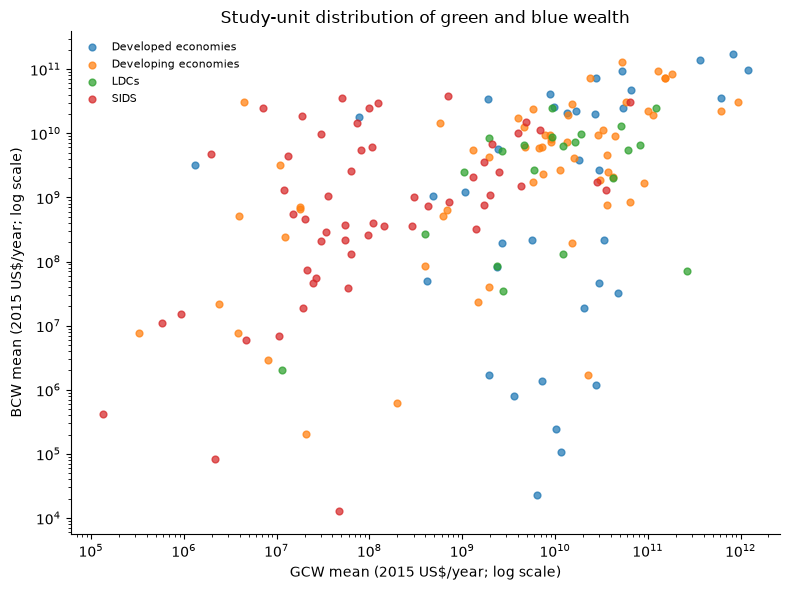

In [5]:
plot_accounts = accounts.copy()
plot_accounts["gcw_plot"] = pd.to_numeric(plot_accounts["gcw_usd2015_yr_mean"], errors="coerce")
plot_accounts["bcw_plot"] = pd.to_numeric(plot_accounts["bcw_usd2015_yr_mean"], errors="coerce")
plot_accounts["group_plot"] = plot_accounts["groups"].fillna("Unclassified")
plot_accounts = plot_accounts.loc[plot_accounts["gcw_plot"].gt(0) & plot_accounts["bcw_plot"].gt(0)]

fig, ax = plt.subplots(figsize=(8, 6))
for group, frame in plot_accounts.groupby("group_plot", dropna=False):
    ax.scatter(frame["gcw_plot"], frame["bcw_plot"], s=24, alpha=0.72, label=group)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("GCW mean (2015 US$/year; log scale)")
ax.set_ylabel("BCW mean (2015 US$/year; log scale)")
ax.set_title("Study-unit distribution of green and blue wealth")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 4. Compare regional profiles and global aggregation

The regional and economic-group summaries show how the aggregate changes when study units are grouped. Percentiles must be computed from the draw-wise global totals; summing separately calculated country percentiles does not produce the same global percentile. These displays help trace that distinction without changing the account definition.

In [6]:
concentration = pd.read_csv(TABLES / 'Supplementary_account_concentration_2024.csv')
regions = pd.read_csv(TABLES / 'Supplementary_region_profiles_2024.csv')
display(concentration)
display(regions)

,measure,n_units,gini,top_10_share_pct,top_50_share_pct,median_usd2015_yr,aggregation_scope
0,GCW,236,0.865217,64.056074,90.630345,3.328198e+09,Available component values by country/territor...
1,BCW,238,0.819707,44.037683,88.040891,4.871137e+08,Available component values by country/territor...
2,NCW,242,0.824403,56.802216,85.462119,7.080594e+09,Country/territory sum of available account com...


,region,units_with_gcw,units_with_bcw,units_with_both_accounts,gcw_trillion_usd2015_yr,bcw_trillion_usd2015_yr,ncw_trillion_usd2015_yr,ncw_complete_case_trillion_usd2015_yr,units_with_2024_gdp,median_gcw_gdp_2024_pct
0,Africa,58,61,58,1.290881,3.659460e-01,1.656827,1.641389,52,32.676573
1,Americas,27,27,27,3.291339,7.082366e-01,3.999575,3.999575,24,26.553477
2,Asia,48,46,46,1.488393,3.812763e-01,1.869669,1.866238,46,4.669130
3,Caribbean,28,28,28,0.016555,5.927372e-02,0.075829,0.075829,20,2.008489
4,Europe,50,50,50,1.707374,4.107565e-01,2.118131,2.118131,44,3.988163
5,Oceania,25,25,23,0.466901,4.038200e-01,0.870721,0.870545,18,10.506201
6,Unclassified,0,1,0,NaN,9.736643e-07,NaN,NaN,0,NaN
7,All units,236,238,232,8.261443,2.329310e+00,10.590753,10.571706,204,7.964063
